In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [12]:
train_df = pd.read_csv("/kaggle/input/datasets/sharanyabhatia/fashion-mnist/fashion-mnist_train.csv")
test_df = pd.read_csv("/kaggle/input/datasets/sharanyabhatia/fashion-mnist/fashion-mnist_test.csv")

X_train = train_df.iloc[:, 1:].values / 255.0
y_train = train_df.iloc[:, 0].values

X_test = test_df.iloc[:, 1:].values / 255.0
y_test = test_df.iloc[:, 0].values

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test), batch_size=128)

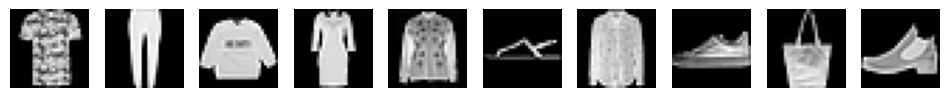

In [13]:
def show_samples():
    fig, axes = plt.subplots(1, 10, figsize=(12,2))
    for i in range(10):
        idx = np.where(y_train == i)[0][0]
        axes[i].imshow(X_train[idx].view(28,28), cmap='gray')
        axes[i].axis('off')
    plt.show()

show_samples()

In [14]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        return out

In [15]:
def train_model(latent_dim, epochs=10):
    model = Autoencoder(latent_dim)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    losses = []

    for epoch in range(epochs):
        total_loss = 0
        for (x,) in train_loader:
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, x)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        losses.append(avg_loss)
        print(f"Latent {latent_dim} | Epoch {epoch+1} | Loss {avg_loss:.4f}")

    return model, losses

In [16]:
small_model, small_loss = train_model(4)
medium_model, medium_loss = train_model(24)
large_model, large_loss = train_model(128)

Latent 4 | Epoch 1 | Loss 0.0326
Latent 4 | Epoch 2 | Loss 0.0222
Latent 4 | Epoch 3 | Loss 0.0212
Latent 4 | Epoch 4 | Loss 0.0206
Latent 4 | Epoch 5 | Loss 0.0203
Latent 4 | Epoch 6 | Loss 0.0200
Latent 4 | Epoch 7 | Loss 0.0199
Latent 4 | Epoch 8 | Loss 0.0197
Latent 4 | Epoch 9 | Loss 0.0196
Latent 4 | Epoch 10 | Loss 0.0195
Latent 24 | Epoch 1 | Loss 0.0313
Latent 24 | Epoch 2 | Loss 0.0166
Latent 24 | Epoch 3 | Loss 0.0144
Latent 24 | Epoch 4 | Loss 0.0132
Latent 24 | Epoch 5 | Loss 0.0124
Latent 24 | Epoch 6 | Loss 0.0118
Latent 24 | Epoch 7 | Loss 0.0114
Latent 24 | Epoch 8 | Loss 0.0110
Latent 24 | Epoch 9 | Loss 0.0108
Latent 24 | Epoch 10 | Loss 0.0105
Latent 128 | Epoch 1 | Loss 0.0306
Latent 128 | Epoch 2 | Loss 0.0161
Latent 128 | Epoch 3 | Loss 0.0135
Latent 128 | Epoch 4 | Loss 0.0119
Latent 128 | Epoch 5 | Loss 0.0108
Latent 128 | Epoch 6 | Loss 0.0099
Latent 128 | Epoch 7 | Loss 0.0093
Latent 128 | Epoch 8 | Loss 0.0087
Latent 128 | Epoch 9 | Loss 0.0082
Latent 128 | 

Small Model


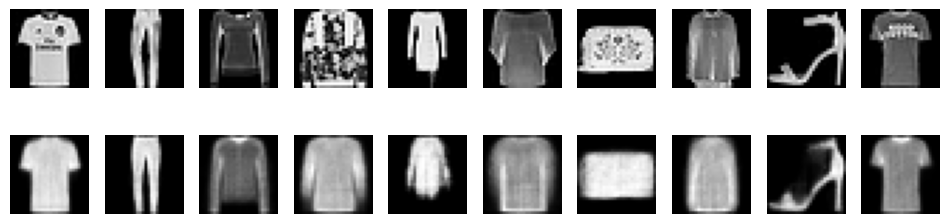

Medium Model


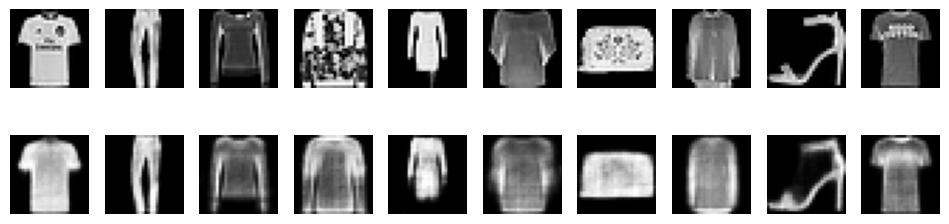

Large Model


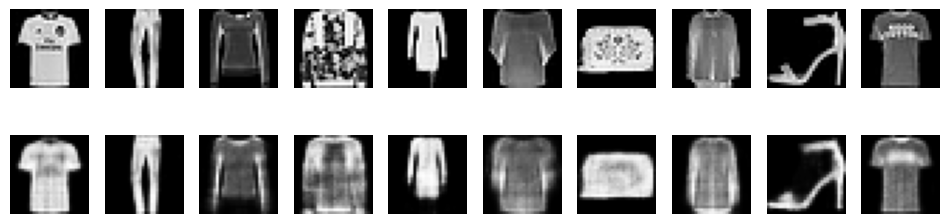

In [17]:
def show_reconstruction(model):
    x = X_test[:10]
    with torch.no_grad():
        recon = model(x)

    fig, axes = plt.subplots(2, 10, figsize=(12,3))
    for i in range(10):
        axes[0,i].imshow(x[i].view(28,28), cmap='gray')
        axes[0,i].axis('off')
        axes[1,i].imshow(recon[i].view(28,28), cmap='gray')
        axes[1,i].axis('off')

    plt.show()

print("Small Model")
show_reconstruction(small_model)
    
print("Medium Model")
show_reconstruction(medium_model)

print("Large Model")
show_reconstruction(large_model)

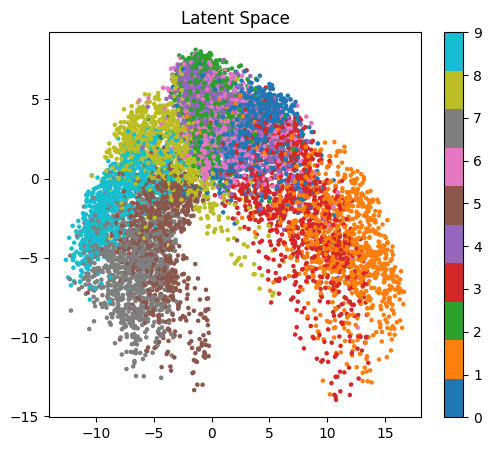

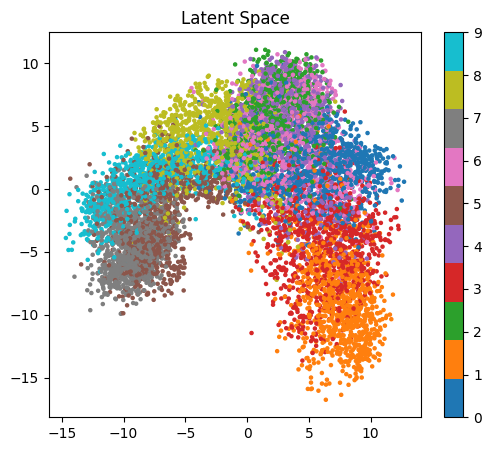

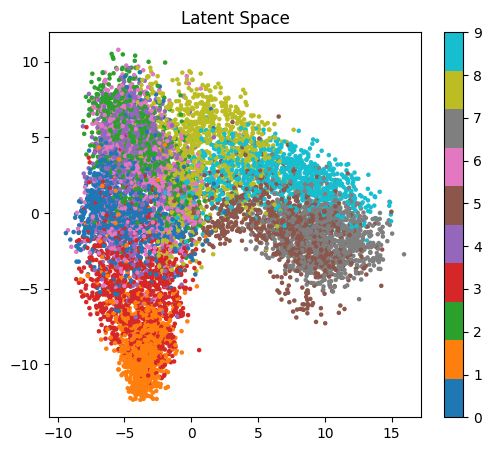

In [18]:
def plot_latent(model):
    with torch.no_grad():
        z = model.encoder(X_test).numpy()

    if z.shape[1] > 2:
        z = PCA(n_components=2).fit_transform(z)

    plt.figure(figsize=(6,5))
    scatter = plt.scatter(z[:,0], z[:,1], c=y_test, cmap='tab10', s=5)
    plt.colorbar(scatter)
    plt.title("Latent Space")
    plt.show()

plot_latent(small_model)
plot_latent(medium_model)
plot_latent(large_model)

Interpolation Small


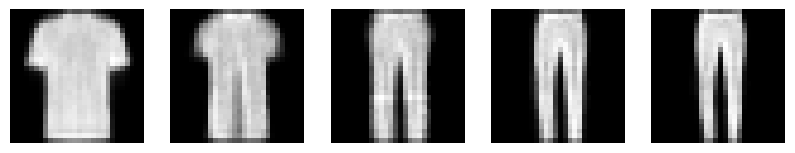

Interpolation Medium


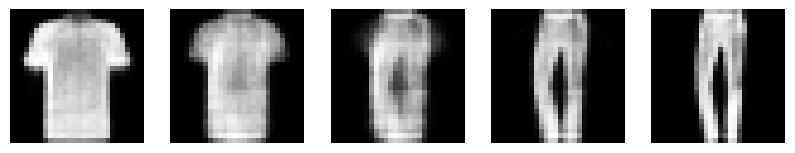

Interpolation Large


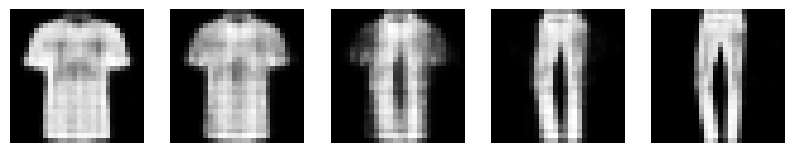

In [19]:
def interpolate(model):
    x1 = X_test[0].unsqueeze(0)
    x2 = X_test[1].unsqueeze(0)

    with torch.no_grad():
        z1 = model.encoder(x1)
        z2 = model.encoder(x2)

    alphas = [0, 0.25, 0.5, 0.75, 1.0]
    images = []

    with torch.no_grad():
        for a in alphas:
            z = (1-a)*z1 + a*z2
            img = model.decoder(z)
            images.append(img)

    fig, axes = plt.subplots(1,5, figsize=(10,2))
    for i, img in enumerate(images):
        axes[i].imshow(img.view(28,28), cmap='gray')
        axes[i].axis('off')
    plt.show()

print("Interpolation Small")
interpolate(small_model)

print("Interpolation Medium")
interpolate(medium_model)

print("Interpolation Large")
interpolate(large_model)